# آمار توصیفی و مصورسازی داده — نوت‌بوک همراه ارائهٔ دوم 📊

**درس داده‌کاوی و یادگیری ماشین** | استاد درس: دکتر محمدرضا سلطان آقایی | ارائه‌دهنده: [نام و نام‌خانوادگی شما]

این نوت‌بوک همراهِ اسلایدهای ۴ تا ۷ ارائهٔ «از داده خام تا مدل قابل‌اعتماد» است: شاخص‌های مرکزیت، شاخص‌های پراکندگی، نمودار جعبه‌ای و دادهٔ پرت، و گالری مصورسازی.

**ساختار:**
۱. مثال کلاسیک درس: دو مدرس، یک میانگین!
۲. شاخص‌های پراکندگی — از دامنه تا ضریب تغییرات
۳. نمودار جعبه‌ای و قاعدهٔ ۱.۵×IQR برای دادهٔ پرت
۴. گالری مصورسازی: هیستوگرام، پراکنش، Q-Q و پارتو
۵. تمرین‌های پیشنهادی
---
### 🛠 راهنمای استفاده
- **ابزار:** همهٔ کدها در **Google Colab** اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: **Shift+Enter** یا منوی Runtime ▸ Run all).
- **یادگیری پایتون، از صفر:** [W3Schools — Python Tutorial](https://www.w3schools.com/python/default.asp) — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.
- **هر سلول:** توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.


## ۱) مثال کلاسیک درس: دو مدرس، یک میانگین!

نمرات ۸ دانشجو نزد دو مدرس — **میانگین هر دو دقیقاً ۱۵ است**، اما آیا این دو کلاس یکسان‌اند؟

In [1]:
# مثال درس: نمرات دو مدرس — میانگین‌ها برابر (۱۵) اما پراکندگی متفاوت
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

teacher_a = np.array([15, 18, 12, 13, 17, 14, 16, 15], dtype=float)   # مدرس الف
teacher_b = np.array([10, 18, 20, 10, 20, 20, 12, 10], dtype=float)   # مدرس ب

df = pd.DataFrame({'مدرس الف': teacher_a, 'مدرس ب': teacher_b},
                  index=[f'دانشجو {i}' for i in range(1, 9)])
df.loc['میانگین'] = [teacher_a.mean(), teacher_b.mean()]
df.round(2)

,مدرس الف,مدرس ب
دانشجو 1,15.0,10.0
دانشجو 2,18.0,18.0
دانشجو 3,12.0,20.0
دانشجو 4,13.0,10.0
دانشجو 5,17.0,20.0
دانشجو 6,14.0,20.0
دانشجو 7,16.0,12.0
دانشجو 8,15.0,10.0
میانگین,15.0,15.0


میانگین‌ها برابرند؛ حالا شاخص‌های مرکزیت را کامل کنیم: **میانه** (برای تعداد زوج، میانگین دو عدد وسط) و **نما** (بیشترین تکرار):

In [2]:
for name, x in [('مدرس الف', teacher_a), ('مدرس ب', teacher_b)]:
    vals, counts = np.unique(x, return_counts=True)
    modes = vals[counts == counts.max()]
    print(f'{name}: میانگین={x.mean():.2f}  میانه={np.median(x):.2f}  نما={modes.tolist()}')
# توجه: نمرات مدرس ب «دونما» است (۱۰ و ۲۰ هر دو ۳ بار تکرار شده‌اند) — نشانهٔ توزیع اریب!

مدرس الف: میانگین=15.00  میانه=15.00  نما=[15.0]
مدرس ب: میانگین=15.00  میانه=15.00  نما=[10.0, 20.0]


## ۲) شاخص‌های پراکندگی — از دامنه تا ضریب تغییرات

همان‌طور که در اسلاید دیدیم، با برابری میانگین‌ها، تفاوت واقعی این دو کلاس در **پراکندگی** است. شش شاخص را حساب می‌کنیم (واریانس جامعه‌ای، هم‌خوان با محاسبهٔ اسلاید درس):

In [3]:
# شاخص‌های پراکندگی برای هر دو مدرس: دامنه، IQR، واریانس، SD و ضریب تغییرات
def dispersion(x):
    x = np.sort(x)
    n = len(x)
    q1 = np.median(x[:n//2]); q3 = np.median(x[(n+1)//2:])   # روش میانهٔ نیمه‌ها (Tukey)
    mean = x.mean()
    return {
        'دامنه (Range)': x.max() - x.min(),
        'IQR': q3 - q1,
        'MD (انحراف از میانگین)': np.abs(x - mean).mean(),
        'واریانس': ((x - mean)**2).mean(),
        'انحراف معیار (SD)': np.sqrt(((x - mean)**2).mean()),
        'CV ضریب تغییرات ٪': np.sqrt(((x - mean)**2).mean()) / mean * 100,
    }

stats = pd.DataFrame({'مدرس الف': dispersion(teacher_a), 'مدرس ب': dispersion(teacher_b)})
stats.round(2)

,مدرس الف,مدرس ب
دامنه (Range),6.00,10.00
IQR,3.00,10.00
MD (انحراف از میانگین),1.50,4.50
واریانس,3.50,21.00
انحراف معیار (SD),1.87,4.58
CV ضریب تغییرات ٪,12.47,30.55


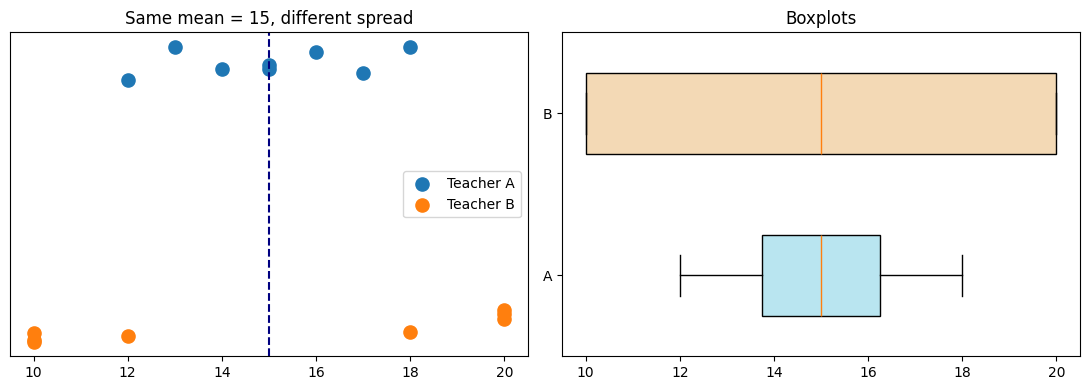

In [4]:
# مقایسهٔ بصری: نمرات پراکندهٔ «ب» در برابر فشردهٔ «الف» + نمودار جعبه‌ای
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(teacher_a, np.ones(8)+np.random.default_rng(1).uniform(-.08,.08,8), s=90, label='Teacher A')
axes[0].scatter(teacher_b, np.zeros(8)+np.random.default_rng(2).uniform(-.08,.08,8), s=90, label='Teacher B')
axes[0].axvline(15, color='navy', ls='--', lw=1.5); axes[0].set_title('Same mean = 15, different spread')
axes[0].legend(); axes[0].set_yticks([])
bp = axes[1].boxplot([teacher_a, teacher_b], vert=False, widths=.5, patch_artist=True)
for patch, c in zip(bp['boxes'], ['#B9E5F0', '#F3D9B5']): patch.set_facecolor(c)
axes[1].set_yticks([1, 2], ['A', 'B']); axes[1].set_title('Boxplots')
plt.tight_layout(); plt.show()

**تفسیر (مطابق اسلاید درس):** همهٔ شاخص‌ها می‌گویند کلاس «ب» حدود ۲ تا ۳ برابر پراکنده‌تر است — شاید نشانهٔ عدم نظم در تدریس! نکتهٔ مهم: **CV بدون واحد است**؛ پس برای مقایسهٔ دو گروه که با واحدهای متفاوت اندازه‌گیری شده‌اند (مثلاً قد بر حسب سانتی‌متر و وزن بر حسب کیلوگرم) تنها گزینهٔ درست است.

## ۳) نمودار جعبه‌ای و قاعدهٔ ۱.۵×IQR برای دادهٔ پرت

خلاصهٔ ۵ عددی (کمینه، Q1، میانه، Q3، بیشینه) و قانون شناسایی دادهٔ پرت:
دادهٔ پرت آن است که از $Q_1 - 1.5\times IQR$ کمتر یا از $Q_3 + 1.5\times IQR$ بیشتر باشد.

Q1=44.2  میانه=49.8  Q3=55.8  IQR=11.6
حد پرت‌بودن: [26.9 , 73.1]  →  داده پرت: [ 73.88559253 103.        ]


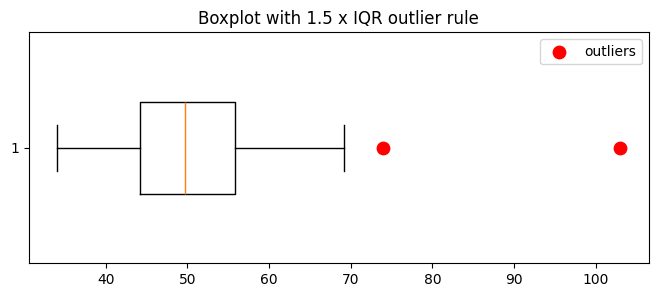

In [5]:
# قاعدهٔ ۱٫۵×IQR برای یافتن دادهٔ پرت (نمرهٔ ۱۰۳ عمداً وارد شده است)
rng = np.random.default_rng(5)
data = np.r_[rng.normal(52, 9, 120), [103]]        # یک دادهٔ پرت عمدی!
q1, med, q3 = np.percentile(data, [25, 50, 75])
iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
outliers = data[(data < lo) | (data > hi)]
print(f'Q1={q1:.1f}  میانه={med:.1f}  Q3={q3:.1f}  IQR={iqr:.1f}')
print(f'حد پرت‌بودن: [{lo:.1f} , {hi:.1f}]  →  داده پرت: {outliers}')

plt.figure(figsize=(8, 3))
plt.boxplot(data, vert=False, widths=.4)
plt.scatter(outliers, [1]*len(outliers), c='red', s=80, zorder=5, label='outliers')
plt.legend(); plt.title('Boxplot with 1.5 x IQR outlier rule')
plt.show()

## ۴) گالری مصورسازی (همان چهار پنل اسلاید ۷)

- **هیستوگرام** — توزیع فراوانی
- **پراکنش + برازش** — رابطهٔ دو متغیر (پایهٔ مدل رگرسیونی)
- **نمودار Q-Q** — بررسی نرمال‌بودن
- **نمودار پارتو** — اولویت‌بندی ۸۰/۲۰ برای متغیرهای اسمی

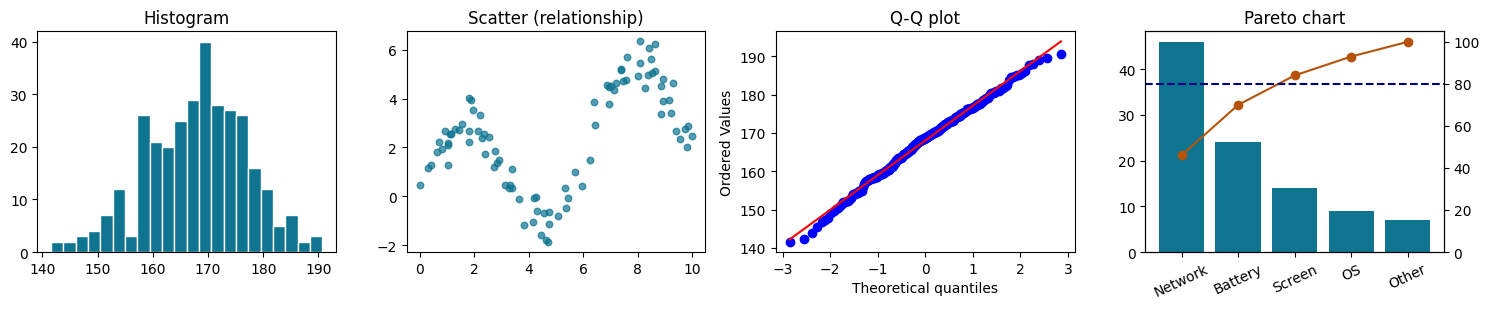

In [6]:
# گالری مصورسازی: هیستوگرام، پراکندگی، Q-Q و پارتو (همان چهار پنل اسلاید ۷)
from scipy import stats as sps
rng = np.random.default_rng(9)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))

xv = rng.normal(168, 9, 320)
axes[0].hist(xv, bins=22, color='#0E7490', edgecolor='white'); axes[0].set_title('Histogram')

xs = rng.uniform(0, 10, 90)
ys = 2.6*np.sin(xs) + .35*xs + rng.normal(0, .5, 90)
axes[1].scatter(xs, ys, s=22, alpha=.7, color='#0E7490'); axes[1].set_title('Scatter (relationship)')

sps.probplot(xv, dist='norm', plot=axes[2]); axes[2].set_title('Q-Q plot')

cats = ['Network', 'Battery', 'Screen', 'OS', 'Other']; cnt = [46, 24, 14, 9, 7]
axes[3].bar(cats, cnt, color='#0E7490')
ax2 = axes[3].twinx()
ax2.plot(cats, np.cumsum(cnt)/sum(cnt)*100, 'o-', color='#B45309')
ax2.axhline(80, ls='--', color='navy'); ax2.set_ylim(0, 105)
axes[3].set_title('Pareto chart'); axes[3].tick_params(axis='x', labelrotation=25)
plt.tight_layout(); plt.show()

## ۵) جمع‌بندی و تمرین‌ها ✅

- میانگین به‌تنهایی گمراه‌کننده است؛ همیشه کنارش **پراکندگی** (IQR، SD، CV) را گزارش کنید.
- **Boxplot** سریع‌ترین «چشمِ اول» است: مرکزیت، پراکندگی، اریبی و دادهٔ پرت را یکجا نشان می‌دهد.
- قاعدهٔ $1.5\times IQR$ ساده‌ترین راه شناسایی خودکار دادهٔ پرت است.

**تمرین‌ها:**
1. آرایهٔ خودتان را با چند دادهٔ پرت بسازید و با قاعدهٔ ۱.۵×IQR آن‌ها را پیدا کنید.
2. برای نمرات دو مدرس، شاخص MAD (انحراف مطلق از **میانه**) را حساب کنید — چرا در این مثال با MD برابر شد؟
3. یک مجموعه‌دادهٔ اریب بسازید و تفاوت میانگین/میانه/نما را در آن ببینید (مانند مدرس ب).
4. با `pandas.DataFrame.plot(kind='box')` نمرات دو مدرس را کنار هم رسم کنید.